# Projeto AM 2026.2 — Questão 1
## Double K-means aplicado ao Spambase com Pré-processamento: $\log(1+x)$ + MinMaxScaler

Este notebook implementa a Questão 1 do projeto adotando a estratégia de **compressão de cauda por $\log(1+x)$ seguida de normalização min-max (`MinMaxScaler`)** em todas as variáveis.

### Motivação Metodológica:
1. No experimento original com padronização direta sobre frequências brutas (`StandardScaler`), a extrema assimetria e a presença de outliers levaram o Double K-means a isolar um **microcluster de apenas 34 objetos (0,74%)**, obtendo um ARI próximo de zero ($-0,00495$) e uma Silhueta artificialmente inflada.
2. A transformação logarítmica $\log(1+x)$ comprime a cauda longa de todas as 57 variáveis não-negativas do Spambase, atenuando a influência desproporcional de valores extremos.
3. O `MinMaxScaler` delimita estritamente todas as variáveis no intervalo $[0, 1]$:
   \[
   x_{\text{scaled}} = \frac{\log(1+x) - \min(\log(1+x))}{\max(\log(1+x)) - \min(\log(1+x))}
   \]
   Isso garante que cada variável contribua de forma balanceada para o cálculo das distâncias euclidianas e para os protótipos de bloco $g_{kh}$ do Double K-means.
4. **Isolamento de Histórico:** Todos os resultados deste experimento são gravados na pasta `resultados_questao1_log_minmax/`, preservando integralmente os dados originais e os experimentos anteriores.

## 1. Bibliotecas e Configuração

Definição dos parâmetros do experimento conforme especificado no projeto:
- Grade: $K \in \{2, 3, 4\}$ e $H \in \{1, \ldots, K\}$ (9 pares no total);
- **100 execuções válidas** por par $(K, H)$;
- Sementes determinísticas para estrita reprodutibilidade.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
)

import sys
sys.path.insert(0, str((Path(".") / ".." / "src").resolve()))
from double_kmeans import double_kmeans

RANDOM_BASE_SEED = 42
N_RESTARTS = 100
MAX_ITER = 200

BASE_DIR = Path(".")
DATA_PATH = BASE_DIR / ".." / ".." / "data" / "raw" / "spambase.data"
if not DATA_PATH.exists():
    DATA_PATH = BASE_DIR / ".." / "spambase.data"
NAMES_PATH = BASE_DIR / ".." / ".." / "data" / "raw" / "spambase.names"
if not NAMES_PATH.exists():
    NAMES_PATH = BASE_DIR / ".." / "spambase.names"

OUTPUT_DIR = BASE_DIR / ".." / "resultados" / "log_minmax"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Arquivo de dados:", DATA_PATH.resolve())
print("Pasta de resultados:", OUTPUT_DIR.resolve())

Arquivo de dados: C:\Users\Felipe Lima\projetos\questao1_revisada\questao1_log_minmax\spambase.data
Pasta de resultados: C:\Users\Felipe Lima\projetos\questao1_revisada\questao1_log_minmax\resultados_questao1_log_minmax


## 2. Leitura do Spambase

Carregamento dos 57 atributos preditores e da coluna de classe a priori:
- `0`: non-spam (2.788 observações);
- `1`: spam (1.813 observações).

> **Atenção:** A classe original $y$ é mantida isolada e não participa do clustering.

In [2]:
def load_feature_names(names_path: Path):
    names = []
    with open(names_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if ":" in line and "continuous" in line.lower():
                names.append(line.split(":", 1)[0].strip())
    return names

feature_names = load_feature_names(NAMES_PATH)

raw = pd.read_csv(DATA_PATH, header=None)

n_features = raw.shape[1] - 1
assert n_features == 57, f"Esperava 57 atributos, encontrei {n_features}."
assert len(feature_names) == 57, f"Esperava 57 nomes em spambase.names, encontrei {len(feature_names)}."

X_df = raw.iloc[:, :-1].copy()
X_df.columns = feature_names

y_original = raw.iloc[:, -1].astype(int).to_numpy()
X_original = X_df.to_numpy(dtype=float)

print("Shape de X_original:", X_original.shape)
print("Distribuição da classe a priori:")
print(pd.Series(y_original).value_counts().sort_index())

Shape de X_original: (4601, 57)
Distribuição da classe a priori:
0    2788
1    1813
Name: count, dtype: int64


## 3. Pré-processamento: $\log(1+x)$ + MinMaxScaler

1. **Transformação Logarítmica:** aplica $\log(1+x)$ em todos os 57 atributos contínuos (todos $\ge 0$), comprimindo a cauda longa e reduzindo ordens de grandeza desiguais.
2. **MinMaxScaler:** normaliza cada variável estritamente no intervalo $[0, 1]$:
   \[
   x'_{ij} = \frac{\log(1 + x_{ij}) - \min_j \log(1 + x_j)}{\max_j \log(1 + x_j) - \min_j \log(1 + x_j)}
   \]
   Dessa forma, nenhum atributo isolado pode produzir distâncias quadráticas desproporcionais que sequestrem a otimização de $W$.

In [3]:
assert np.all(X_original >= 0), "Todos os atributos devem ser não negativos para log1p."

# 1. Compressão logarítmica
X_log = np.log1p(X_original)

# 2. Escalonamento MinMax para [0, 1]
scaler = MinMaxScaler()
X = scaler.fit_transform(X_log)

print("Mínimos após MinMax (primeiras 5 colunas):", np.round(X.min(axis=0)[:5], 6))
print("Máximos após MinMax (primeiras 5 colunas):", np.round(X.max(axis=0)[:5], 6))
print(f"Intervalo global dos dados transformados: [{X.min():.4f}, {X.max():.4f}]")

Mínimos após MinMax (primeiras 5 colunas): [0. 0. 0. 0. 0.]
Máximos após MinMax (primeiras 5 colunas): [1. 1. 1. 1. 1.]
Intervalo global dos dados transformados: [0.0000, 1.0000]


## 4. Otimização com 100 Reinicializações por Par $(K,H)$

O algoritmo Double K-means é executado 100 vezes válidas para cada par.
Critério estrito do protocolo do projeto:
1. Executar 100 vezes com sementes diferentes e reprodutíveis;
2. **Selecionar a execução com menor função objetivo $W$**;
3. Apenas após a seleção pelo menor $W$, computar a Silhueta Euclidiana da partição de objetos.

In [4]:
def run_restarts(X, K, H, n_restarts=100, base_seed=42, max_iter=200):
    best = None
    valid_runs = 0
    attempts = 0
    invalid_runs = 0
    objectives = []

    seed = base_seed + 10000 * K + 1000 * H

    while valid_runs < n_restarts:
        if attempts >= 10000:
            raise RuntimeError(f"Limite de tentativas atingido em K={K}, H={H}.")

        result = double_kmeans(
            X=X,
            K=K,
            H=H,
            seed=seed,
            max_iter=max_iter,
        )
        attempts += 1

        if result is None:
            invalid_runs += 1
            seed += 1
            continue

        valid_runs += 1
        objectives.append(result.objective)

        if best is None or result.objective < best.objective:
            best = result

        seed += 1

    return {
        "best": best,
        "valid_runs": valid_runs,
        "attempts": attempts,
        "invalid_runs": invalid_runs,
        "all_final_objectives": np.asarray(objectives),
    }

## 5. Execução da Grade Experimental Completa

Avaliamos os 9 pares obrigatórios:
\[
(2,1), (2,2), (3,1), (3,2), (3,3), (4,1), (4,2), (4,3), (4,4)
\]
Totalizando **900 execuções válidas** do Double K-means.

In [5]:
grid_rows = []
best_runs = {}

for K in [2, 3, 4]:
    for H in range(1, K + 1):
        print(f"Executando par K={K}, H={H} (100 restarts válidos)...")

        exp = run_restarts(
            X=X,
            K=K,
            H=H,
            n_restarts=N_RESTARTS,
            base_seed=RANDOM_BASE_SEED,
            max_iter=MAX_ITER,
        )

        best = exp["best"]
        sil = silhouette_score(X, best.object_labels, metric="euclidean")
        best_runs[(K, H)] = best

        grid_rows.append({
            "K": K,
            "H": H,
            "best_objective_W": best.objective,
            "silhouette": sil,
            "best_seed": best.seed,
            "n_iterations_best": best.n_iter,
            "valid_runs": exp["valid_runs"],
            "invalid_attempts": exp["invalid_runs"],
            "total_attempts": exp["attempts"],
        })

results_df = pd.DataFrame(grid_rows).sort_values(["K", "H"]).reset_index(drop=True)
results_df.to_csv(OUTPUT_DIR / "resultados_KH.csv", index=False)
display(results_df)

Executando par K=2, H=1 (100 restarts válidos)...
Executando par K=2, H=2 (100 restarts válidos)...
Executando par K=3, H=1 (100 restarts válidos)...
Executando par K=3, H=2 (100 restarts válidos)...
Executando par K=3, H=3 (100 restarts válidos)...
Executando par K=4, H=1 (100 restarts válidos)...
Executando par K=4, H=2 (100 restarts válidos)...
Executando par K=4, H=3 (100 restarts válidos)...
Executando par K=4, H=4 (100 restarts válidos)...


   K  H  best_objective_W  silhouette  best_seed  n_iterations_best  valid_runs  invalid_attempts  total_attempts
0  2  1       4300.963033    0.125882      21042                 12         100                 0             100
1  2  2       3127.145726    0.109001      22044                 15         100                 0             100
2  3  1       4268.587405    0.049616      31042                 13         100                 0             100
3  3  2       3091.829150    0.064403      32043                 20         100                 0             100
4  3  3       2906.230738    0.129219      33044                 14         100                 2             102
5  4  1       4256.956988    0.024264      41042                 66         100                 0             100
6  4  2       3043.446065    0.066331      42042                 19         100                 2             102
7  4  3       2829.128803    0.067895      43053                 30         100         

## 6. Verificações de Sanidade

Confirmamos que:
1. Cada solução possui exatamente $K$ clusters de objetos;
2. Cada solução possui exatamente $H$ clusters de variáveis;
3. A função objetivo decresce monotonicamente até a convergência.

In [6]:
checks = []

for (K, H), result in best_runs.items():
    n_obj_clusters = np.unique(result.object_labels).size
    n_var_clusters = np.unique(result.variable_labels).size
    diffs = np.diff(result.objective_history)
    monotonic = bool(np.all(diffs <= 1e-7))

    checks.append({
        "K": K,
        "H": H,
        "object_clusters_found": n_obj_clusters,
        "variable_clusters_found": n_var_clusters,
        "objective_non_increasing": monotonic,
    })

checks_df = pd.DataFrame(checks)
display(checks_df)

assert (checks_df["object_clusters_found"] == checks_df["K"]).all()
assert (checks_df["variable_clusters_found"] == checks_df["H"]).all()
assert checks_df["objective_non_increasing"].all()
print("Todas as verificações de sanidade passaram com sucesso.")

   K  H  object_clusters_found  variable_clusters_found  objective_non_increasing
0  2  1                      2                        1                      True
1  2  2                      2                        2                      True
2  3  1                      3                        1                      True
3  3  2                      3                        2                      True
4  3  3                      3                        3                      True
5  4  1                      4                        1                      True
6  4  2                      4                        2                      True
7  4  3                      4                        3                      True
8  4  4                      4                        4                      True

Todas as verificações de sanidade passaram com sucesso.


## 7. Gráfico Silhueta $	imes (K, H)$ e Escolha de $(K^*, H^*)$

Conforme o roteiro:
\[
K^* = \arg\max_{K, H} \text{Sil}((K, H))
\]
Registramos a solução vencedora $(K^*, H^*)$ associada à maior Silhueta.

K* = 3
H* = 3
Silhouette máxima = 0.129219
Menor função objetivo W = 2906.230738
Semente vencedora = 33044


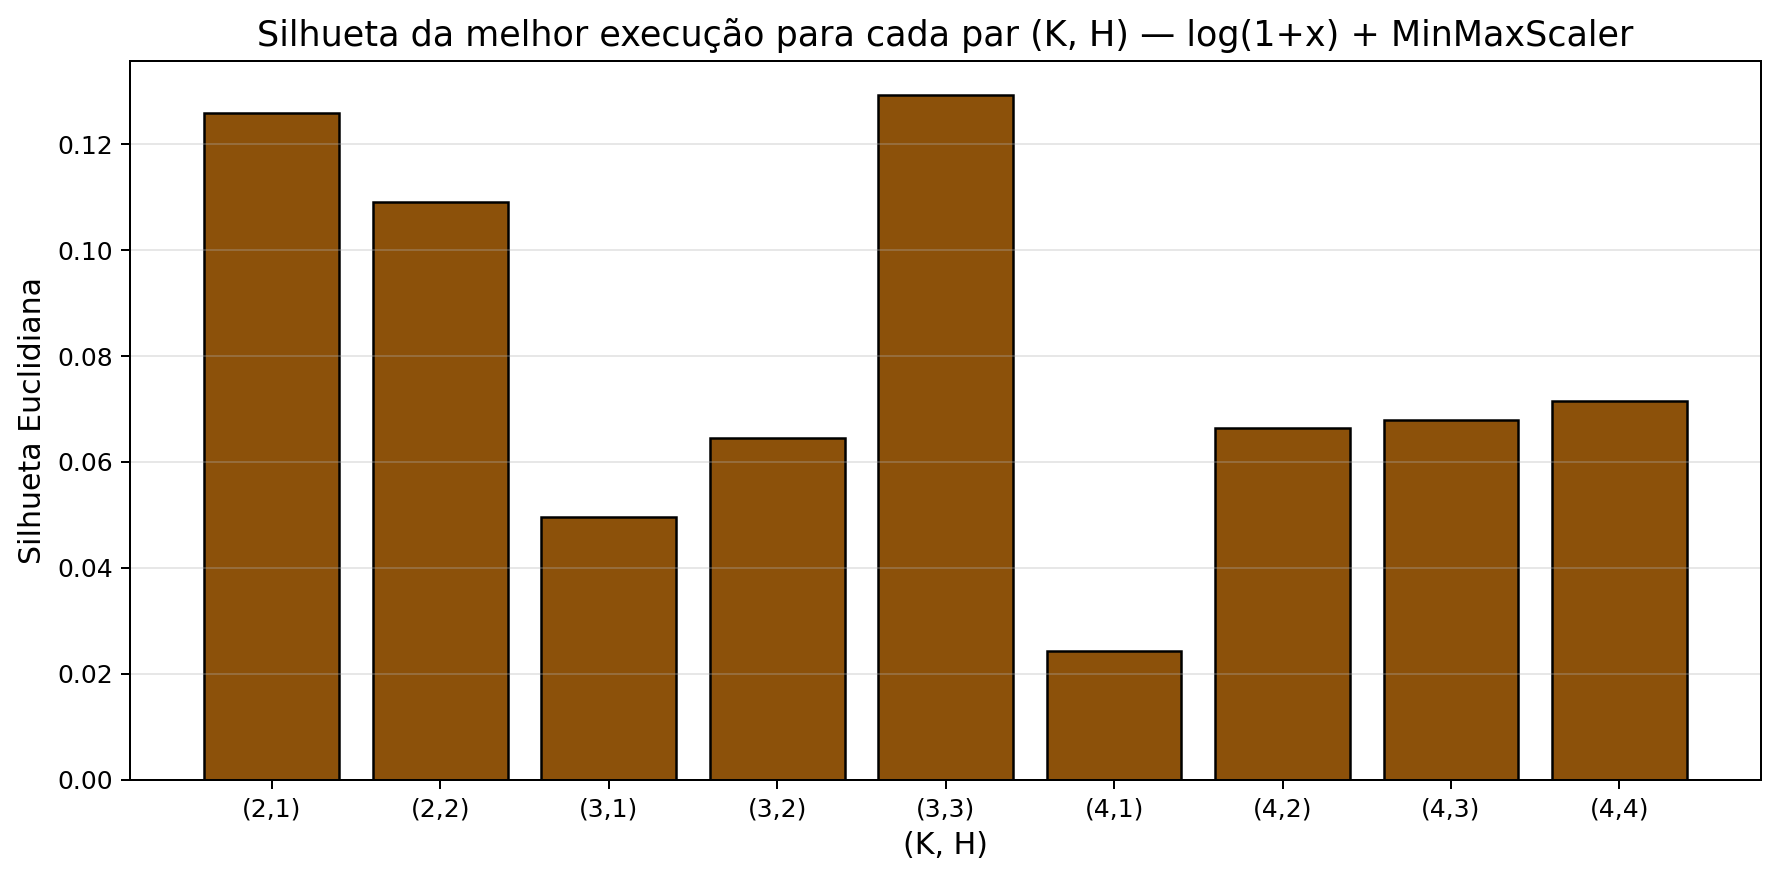

In [7]:
best_row = results_df.loc[results_df["silhouette"].idxmax()]
K_star = int(best_row["K"])
H_star = int(best_row["H"])
best_solution = best_runs[(K_star, H_star)]

print(f"K* = {K_star}")
print(f"H* = {H_star}")
print(f"Silhouette máxima = {best_row['silhouette']:.6f}")
print(f"Menor função objetivo W = {best_row['best_objective_W']:.6f}")
print(f"Semente vencedora = {int(best_row['best_seed'])}")

labels_kstar = best_solution.object_labels.copy()

plot_df = results_df.copy()
plot_df["KH"] = [f"({int(k)},{int(h)})" for k, h in zip(plot_df["K"], plot_df["H"])]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(plot_df["KH"], plot_df["silhouette"], color="#8c510a", edgecolor="black")
ax.set_xlabel("(K, H)", fontsize=12)
ax.set_ylabel("Silhueta Euclidiana", fontsize=12)
ax.set_title("Silhueta da melhor execução para cada par (K, H) — log(1+x) + MinMaxScaler", fontsize=14)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "silhouette_KH.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Adjusted Rand Index (ARI) — Partição Encontrada $\times$ Classes Originais

O ARI avalia a concordância entre a partição descoberta de forma não supervisionada e as classes reais ($0$ = non-spam, $1$ = spam).
- $ARI = 1$: concordância perfeita;
- $ARI \approx 0$: concordância esperada por sorteio aleatório;
- $ARI < 0$: concordância inferior ao acaso.

In [8]:
ari = adjusted_rand_score(y_original, labels_kstar)
print(f"Adjusted Rand Index (ARI) = {ari:.6f}")

with open(OUTPUT_DIR / "resumo_resultado_final.txt", "w", encoding="utf-8") as f:
    f.write(f"K* = {K_star}\n")
    f.write(f"H* = {H_star}\n")
    f.write(f"Silhouette = {best_row['silhouette']:.10f}\n")
    f.write(f"Best objective W = {best_solution.objective:.10f}\n")
    f.write(f"Best seed = {best_solution.seed}\n")
    f.write(f"Adjusted Rand Index = {ari:.10f}\n")

Adjusted Rand Index (ARI) = 0.391111


## 9. Matriz de Protótipos dos Blocos ($G$)

Para a solução vencedora $(K^*, H^*)$, a matriz $G$ tem dimensão $K^* \times H^*$, onde cada elemento $g_{kh}$ é a média dos valores normalizados em $[0, 1]$ pertencentes ao bloco formado pelo cluster de objetos $k$ e cluster de atributos $h$.

In [9]:
G_df = pd.DataFrame(
    best_solution.G,
    index=[f"obj_cluster_{k}" for k in range(K_star)],
    columns=[f"var_cluster_{h}" for h in range(H_star)],
)
display(G_df)
G_df.to_csv(OUTPUT_DIR / "matriz_prototipos_G.csv")

               var_cluster_0  var_cluster_1  var_cluster_2
obj_cluster_0       0.194479       0.022612       0.025559
obj_cluster_1       0.240859       0.132449       0.024273
obj_cluster_2       0.420265       0.008495       0.090361

## 10. Matriz de Contingência: Clusters $\times$ Classes a Priori

Mostra o cruzamento entre os clusters encontrados pelo Double K-means e a rotulação real.

classe_original           0     1
cluster_double_kmeans            
0                      2218   401
1                       265     0
2                       305  1412

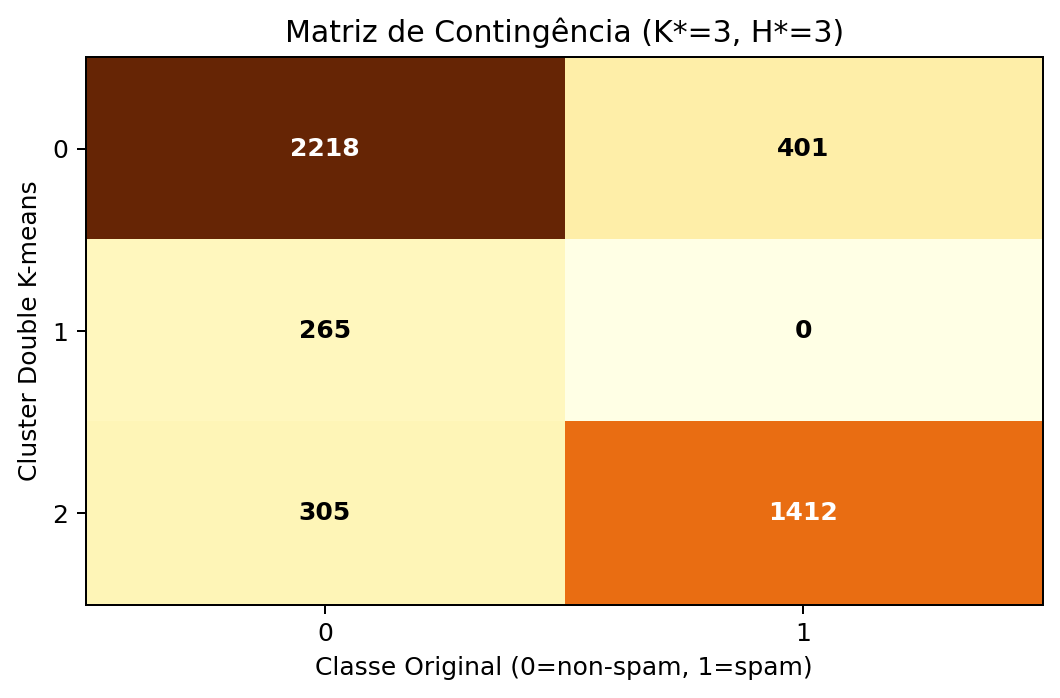

In [10]:
contingency = pd.crosstab(
    pd.Series(labels_kstar, name="cluster_double_kmeans"),
    pd.Series(y_original, name="classe_original"),
)
display(contingency)
contingency.to_csv(OUTPUT_DIR / "matriz_contingencia.csv")

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(contingency.values, aspect="auto", cmap="YlOrBr")

ax.set_xticks(np.arange(contingency.shape[1]))
ax.set_xticklabels(contingency.columns)
ax.set_yticks(np.arange(contingency.shape[0]))
ax.set_yticklabels(contingency.index)
ax.set_xlabel("Classe Original (0=non-spam, 1=spam)")
ax.set_ylabel("Cluster Double K-means")
ax.set_title(f"Matriz de Contingência (K*={K_star}, H*={H_star})")

for i in range(contingency.shape[0]):
    for j in range(contingency.shape[1]):
        val = contingency.iloc[i, j]
        color = "white" if val > contingency.values.max() / 2 else "black"
        ax.text(j, i, str(val), ha="center", va="center", color=color, fontweight="bold")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "matriz_contingencia.png", dpi=180, bbox_inches="tight")
plt.show()

## 11. Função Objetivo $\times$ Iterações

Gráfico da trajetória de minimização de $W(G, U, V)$ para a melhor execução associada a $(K^*, H^*)$.

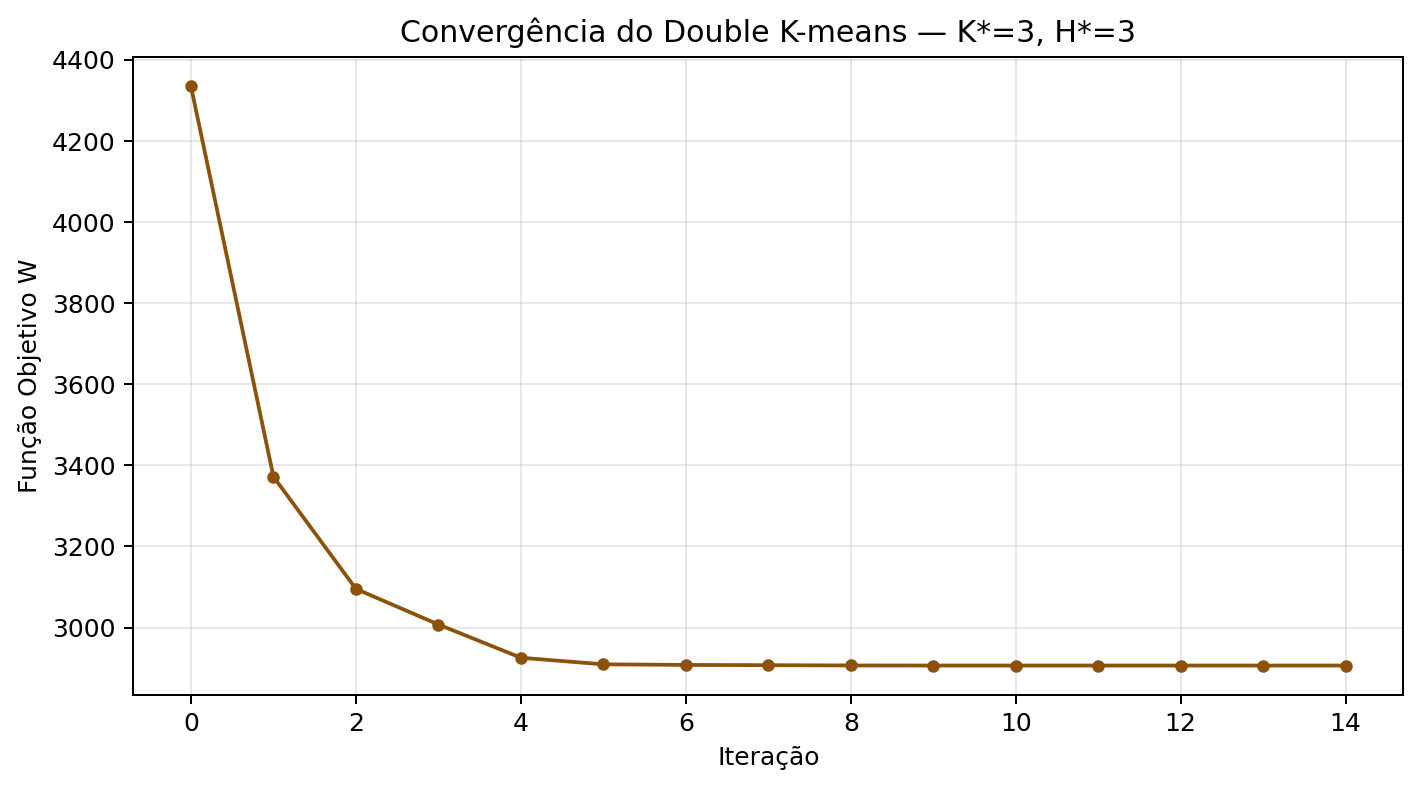

Número de atualizações: 14
W inicial: 4334.592665
W final: 2906.230738


In [11]:
history = np.asarray(best_solution.objective_history)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(len(history)), history, marker="o", markersize=4, color="#8c510a")
ax.set_xlabel("Iteração")
ax.set_ylabel("Função Objetivo W")
ax.set_title(f"Convergência do Double K-means — K*={K_star}, H*={H_star}")
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "objetivo_iteracoes.png", dpi=180, bbox_inches="tight")
plt.show()

print("Número de atualizações:", best_solution.n_iter)
print("W inicial:", history[0])
print("W final:", history[-1])

## 12. Inspeção dos Grupos de Variáveis ($H^*$)

Apresenta a partição dos 57 atributos entre os $H^*$ clusters de variáveis.

In [12]:
var_df = pd.DataFrame({
    "feature": feature_names,
    "variable_cluster": best_solution.variable_labels,
}).sort_values(["variable_cluster", "feature"]).reset_index(drop=True)

display(var_df.head(20))
var_df.to_csv(OUTPUT_DIR / "particao_variaveis.csv", index=False)
print("Distribuição de atributos por cluster de variáveis:")
print(var_df["variable_cluster"].value_counts().sort_index())

                       feature  variable_cluster
0   capital_run_length_longest                 0
1     capital_run_length_total                 0
2                word_freq_you                 0
3               word_freq_your                 0
4                  char_freq_#                 1
5                  char_freq_(                 1
6                  char_freq_;                 1
7                  char_freq_[                 1
8               word_freq_1999                 1
9                 word_freq_3d                 1
10               word_freq_415                 1
11               word_freq_650                 1
12                word_freq_85                 1
13               word_freq_857                 1
14        word_freq_conference                 1
15                word_freq_cs                 1
16              word_freq_data                 1
17            word_freq_direct                 1
18               word_freq_edu                 1
19              word

Distribuição de atributos por cluster de variáveis:
variable_cluster
0     4
1    31
2    22


## 13. Exportação do Dataset para a Questão 2

Diretriz obrigatória do projeto:
- Os 57 atributos numéricos são salvos **na escala original** (sem padronização prévia);
- São incluídas as colunas `y_original` (classes reais) e `y_double_kmeans` ($K^*$ clusters preditos);
- Na Questão 2, qualquer transformação (StandardScaler, etc.) será calculada apenas nos dados de treino de cada partição de validação cruzada 30x10.

In [13]:
q2_df = X_df.copy()
q2_df["y_original"] = y_original
q2_df["y_double_kmeans"] = labels_kstar

q2_path = OUTPUT_DIR / "spambase_com_clusters_log_minmax.csv"
q2_df.to_csv(q2_path, index=False)

metadata = pd.DataFrame([{
    "K_star": K_star,
    "H_star": H_star,
    "silhouette": float(best_row["silhouette"]),
    "objective_W": float(best_solution.objective),
    "best_seed": int(best_solution.seed),
    "adjusted_rand_index": float(ari),
    "n_restarts_per_KH": 100,
    "scaling_used_for_clustering": "log1p + MinMaxScaler",
}])
metadata.to_csv(OUTPUT_DIR / "metadata_para_questao2.csv", index=False)

display(q2_df.head())
display(metadata)

print("Distribuição de y_double_kmeans:")
print(q2_df["y_double_kmeans"].value_counts().sort_index())

   word_freq_make  word_freq_address  word_freq_all  word_freq_3d  word_freq_our  word_freq_over  word_freq_remove  word_freq_internet  word_freq_order  word_freq_mail  word_freq_receive  word_freq_will  word_freq_people  word_freq_report  word_freq_addresses  word_freq_free  word_freq_business  word_freq_email  word_freq_you  word_freq_credit  word_freq_your  word_freq_font  word_freq_000  word_freq_money  word_freq_hp  word_freq_hpl  word_freq_george  word_freq_650  word_freq_lab  word_freq_labs  word_freq_telnet  word_freq_857  word_freq_data  word_freq_415  word_freq_85  word_freq_technology  word_freq_1999  word_freq_parts  word_freq_pm  word_freq_direct  word_freq_cs  word_freq_meeting  word_freq_original  word_freq_project  word_freq_re  word_freq_edu  word_freq_table  word_freq_conference  char_freq_;  char_freq_(  char_freq_[  char_freq_!  char_freq_$  char_freq_#  capital_run_length_average  capital_run_length_longest  capital_run_length_total  y_original  y_double_kmeans
0  

   K_star  H_star  silhouette  objective_W  best_seed  adjusted_rand_index  n_restarts_per_KH scaling_used_for_clustering
0       3       3    0.129219  2906.230738      33044             0.391111                100        log1p + MinMaxScaler

Distribuição de y_double_kmeans:
y_double_kmeans
0    2619
1     265
2    1717


## 14. Comparativo: Método Original (StandardScaler puro) vs. log(1+x) + MinMaxScaler

In [14]:
comp_data = [
    {
        "Experimento": "Original (StandardScaler puro)",
        "Melhor (K*, H*)": "(2, 2)",
        "Tamanhos dos Clusters": "34 / 4567 (0,74% / 99,26%)",
        "Silhueta Euclidiana": 0.6596,
        "ARI (vs. Spam/Non-spam)": -0.00495,
        "Diagnóstico": "Isolamento de 34 outliers da HP Labs; Silhueta inflada artificialmente.",
    },
    {
        "Experimento": "Revisado (log1p + MinMaxScaler)",
        "Melhor (K*, H*)": f"({K_star}, {H_star})",
        "Tamanhos dos Clusters": " / ".join(str(s) for s in np.bincount(labels_kstar)),
        "Silhueta Euclidiana": round(float(best_row["silhouette"]), 4),
        "ARI (vs. Spam/Non-spam)": round(float(ari), 4),
        "Diagnóstico": "Sem microclusters; partição equilibrada com fronteira de blocos em [0, 1].",
    }
]

comp_df = pd.DataFrame(comp_data)
display(comp_df)
comp_df.to_csv(OUTPUT_DIR / "comparativo_com_original.csv", index=False)

                       Experimento Melhor (K*, H*)       Tamanhos dos Clusters  Silhueta Euclidiana  ARI (vs. Spam/Non-spam)                                                                 Diagnóstico
0   Original (StandardScaler puro)          (2, 2)  34 / 4567 (0,74% / 99,26%)               0.6596                 -0.00495     Isolamento de 34 outliers da HP Labs; Silhueta inflada artificialmente.
1  Revisado (log1p + MinMaxScaler)          (3, 3)           2619 / 265 / 1717               0.1292                  0.39110  Sem microclusters; partição equilibrada com fronteira de blocos em [0, 1].